In [29]:
#importing all necessary imports
from imblearn.over_sampling import ADASYN
from sklearn.preprocessing import LabelEncoder , StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score , classification_report , confusion_matrix
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import joblib



In [2]:
#importing the train dataset 
df = pd.read_csv("datasets/train.csv").drop(columns=['User_ID'])
df.head(10)

,Age,Gender,Platform,Daily_Usage_Time (minutes),Posts_Per_Day,Likes_Received_Per_Day,Comments_Received_Per_Day,Messages_Sent_Per_Day,Dominant_Emotion
0,25,Female,Instagram,120.0,3.0,45.0,10.0,12.0,Happiness
1,30,Male,Twitter,90.0,5.0,20.0,25.0,30.0,Anger
2,22,Male,Facebook,60.0,2.0,15.0,5.0,20.0,Neutral
3,28,Female,Instagram,200.0,8.0,100.0,30.0,50.0,Anxiety
4,33,Male,LinkedIn,45.0,1.0,5.0,2.0,10.0,Boredom
5,21,Male,Instagram,150.0,4.0,60.0,15.0,25.0,Happiness
6,27,Female,Twitter,85.0,3.0,30.0,10.0,18.0,Anger
7,24,Male,Facebook,110.0,6.0,25.0,12.0,22.0,Sadness
8,29,Female,LinkedIn,55.0,2.0,10.0,3.0,8.0,Neutral
9,31,Male,Instagram,170.0,5.0,80.0,20.0,35.0,Happiness


In [3]:
#importing the test dataset 
df_test = pd.read_csv("datasets/test.csv").drop(columns=['User_ID'])
df_test.head(10)

,Age,Gender,Platform,Daily_Usage_Time (minutes),Posts_Per_Day,Likes_Received_Per_Day,Comments_Received_Per_Day,Messages_Sent_Per_Day,Dominant_Emotion
0,27,Female,Snapchat,120,4,40,18,22,Neutral
1,21,Male,Snapchat,60,1,18,7,12,Neutral
2,28,Male,Snapchat,115,3,38,18,27,Anxiety
3,27,Male,Telegram,105,3,48,20,28,Anxiety
4,21,Female,Facebook,55,3,17,7,12,Neutral
5,25,Female,Instagram,160,6,85,26,30,Happiness
6,25,Female,Instagram,160,6,85,26,30,Happiness
7,21,Female,Facebook,55,3,17,7,12,Neutral
8,24,Female,Snapchat,85,3,33,20,18,Happiness
9,33,Male,LinkedIn,45,1,10,5,12,Boredom


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1001 entries, 0 to 1000
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         1001 non-null   object 
 1   Gender                      1000 non-null   object 
 2   Platform                    1000 non-null   object 
 3   Daily_Usage_Time (minutes)  1000 non-null   float64
 4   Posts_Per_Day               1000 non-null   float64
 5   Likes_Received_Per_Day      1000 non-null   float64
 6   Comments_Received_Per_Day   1000 non-null   float64
 7   Messages_Sent_Per_Day       1000 non-null   float64
 8   Dominant_Emotion            1000 non-null   object 
dtypes: float64(5), object(4)
memory usage: 70.5+ KB


In [5]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Age                         101 non-null    int64 
 1   Gender                      101 non-null    object
 2   Platform                    101 non-null    object
 3   Daily_Usage_Time (minutes)  101 non-null    int64 
 4   Posts_Per_Day               101 non-null    int64 
 5   Likes_Received_Per_Day      101 non-null    int64 
 6   Comments_Received_Per_Day   101 non-null    int64 
 7   Messages_Sent_Per_Day       101 non-null    int64 
 8   Dominant_Emotion            101 non-null    object
dtypes: int64(6), object(3)
memory usage: 7.2+ KB


In [6]:
#Dropping the falty row
df.dropna(inplace = True)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1000 entries, 0 to 1000
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         1000 non-null   object 
 1   Gender                      1000 non-null   object 
 2   Platform                    1000 non-null   object 
 3   Daily_Usage_Time (minutes)  1000 non-null   float64
 4   Posts_Per_Day               1000 non-null   float64
 5   Likes_Received_Per_Day      1000 non-null   float64
 6   Comments_Received_Per_Day   1000 non-null   float64
 7   Messages_Sent_Per_Day       1000 non-null   float64
 8   Dominant_Emotion            1000 non-null   object 
dtypes: float64(5), object(4)
memory usage: 78.1+ KB


In [7]:
#checking on the Age column
df["Age"].value_counts()

Age
27        92
28        92
29        90
22        74
26        66
24        64
25        64
31        62
21        56
33        56
30        48
23        48
Male      40
35        38
32        38
34        36
Female    36
Name: count, dtype: int64

In [8]:
# Function to swap incorrect 'Age' and 'Gender' values
def swap_incorrect_values(row):
    # Check if 'Age' is 'Male' or 'Female', indicating a swap is needed
    if row['Age'] == 'Male' or row['Age'] == 'Female':
        row['Age'], row['Gender'] = row['Gender'], row['Age']
    return row

# Apply the function to each row of the DataFrame
df = df.apply(swap_incorrect_values, axis=1)
df["Age"].value_counts()

Age
28    100
27    100
29    100
22     80
25     70
24     70
31     70
26     70
33     60
21     60
30     50
23     50
34     40
35     40
32     40
Name: count, dtype: int64

In [9]:
df_test["Age"].value_counts()

Age
28    13
27    12
23    11
31    10
29    10
26     8
25     6
24     6
21     5
32     4
22     4
33     3
35     3
34     3
30     3
Name: count, dtype: int64

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1000 entries, 0 to 1000
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         1000 non-null   object 
 1   Gender                      1000 non-null   object 
 2   Platform                    1000 non-null   object 
 3   Daily_Usage_Time (minutes)  1000 non-null   float64
 4   Posts_Per_Day               1000 non-null   float64
 5   Likes_Received_Per_Day      1000 non-null   float64
 6   Comments_Received_Per_Day   1000 non-null   float64
 7   Messages_Sent_Per_Day       1000 non-null   float64
 8   Dominant_Emotion            1000 non-null   object 
dtypes: float64(5), object(4)
memory usage: 78.1+ KB


In [11]:
#converting numerical columns to integer
columns = ['Age','Daily_Usage_Time (minutes)','Posts_Per_Day','Likes_Received_Per_Day','Comments_Received_Per_Day','Messages_Sent_Per_Day']

for col in columns:
    df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)
    df_test[col] = pd.to_numeric(df_test[col], errors='coerce').fillna(0).astype(int)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1000 entries, 0 to 1000
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Age                         1000 non-null   int32 
 1   Gender                      1000 non-null   object
 2   Platform                    1000 non-null   object
 3   Daily_Usage_Time (minutes)  1000 non-null   int32 
 4   Posts_Per_Day               1000 non-null   int32 
 5   Likes_Received_Per_Day      1000 non-null   int32 
 6   Comments_Received_Per_Day   1000 non-null   int32 
 7   Messages_Sent_Per_Day       1000 non-null   int32 
 8   Dominant_Emotion            1000 non-null   object
dtypes: int32(6), object(3)
memory usage: 54.7+ KB


In [13]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Age                         101 non-null    int32 
 1   Gender                      101 non-null    object
 2   Platform                    101 non-null    object
 3   Daily_Usage_Time (minutes)  101 non-null    int32 
 4   Posts_Per_Day               101 non-null    int32 
 5   Likes_Received_Per_Day      101 non-null    int32 
 6   Comments_Received_Per_Day   101 non-null    int32 
 7   Messages_Sent_Per_Day       101 non-null    int32 
 8   Dominant_Emotion            101 non-null    object
dtypes: int32(6), object(3)
memory usage: 4.9+ KB


In [14]:
#encoding all the categorical data
platform_encoder = LabelEncoder()
gender_encoder = LabelEncoder()
emotion_encoder = LabelEncoder()

df["Platform"] = platform_encoder.fit_transform(df["Platform"])
df["Gender"] = gender_encoder.fit_transform(df["Gender"])
df["Dominant_Emotion"] = emotion_encoder.fit_transform(df["Dominant_Emotion"])

df_test["Platform"] = platform_encoder.transform(df_test["Platform"])
df_test["Gender"] = gender_encoder.transform(df_test["Gender"])
df_test["Dominant_Emotion"] = emotion_encoder.transform(df_test["Dominant_Emotion"])

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1000 entries, 0 to 1000
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Age                         1000 non-null   int32
 1   Gender                      1000 non-null   int32
 2   Platform                    1000 non-null   int32
 3   Daily_Usage_Time (minutes)  1000 non-null   int32
 4   Posts_Per_Day               1000 non-null   int32
 5   Likes_Received_Per_Day      1000 non-null   int32
 6   Comments_Received_Per_Day   1000 non-null   int32
 7   Messages_Sent_Per_Day       1000 non-null   int32
 8   Dominant_Emotion            1000 non-null   int32
dtypes: int32(9)
memory usage: 43.0 KB


In [15]:
df.sample(10)

,Age,Gender,Platform,Daily_Usage_Time (minutes),Posts_Per_Day,Likes_Received_Per_Day,Comments_Received_Per_Day,Messages_Sent_Per_Day,Dominant_Emotion
97,35,1,6,110,3,45,20,25,3
12,34,1,2,65,1,12,4,15,2
931,34,0,2,65,2,17,5,14,2
369,22,1,3,75,2,21,8,20,5
63,26,0,3,120,4,50,15,30,1
51,24,0,5,75,3,29,15,19,0
676,28,1,3,115,3,38,18,27,1
933,23,1,5,70,3,30,14,18,4
605,21,1,1,150,5,65,25,30,3
794,29,0,3,95,2,23,10,28,5


In [16]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Age                         101 non-null    int32
 1   Gender                      101 non-null    int32
 2   Platform                    101 non-null    int32
 3   Daily_Usage_Time (minutes)  101 non-null    int32
 4   Posts_Per_Day               101 non-null    int32
 5   Likes_Received_Per_Day      101 non-null    int32
 6   Comments_Received_Per_Day   101 non-null    int32
 7   Messages_Sent_Per_Day       101 non-null    int32
 8   Dominant_Emotion            101 non-null    int32
dtypes: int32(9)
memory usage: 3.7 KB


In [17]:
df_test.sample(10)

,Age,Gender,Platform,Daily_Usage_Time (minutes),Posts_Per_Day,Likes_Received_Per_Day,Comments_Received_Per_Day,Messages_Sent_Per_Day,Dominant_Emotion
5,25,0,1,160,6,85,26,30,3
99,24,1,4,75,3,37,16,22,4
100,27,1,0,60,1,10,4,15,2
68,23,1,0,105,2,25,12,18,4
91,29,0,0,60,1,12,4,12,2
84,26,1,5,75,2,23,12,18,5
69,30,1,1,175,7,100,33,38,3
79,29,0,3,90,3,22,10,21,5
18,28,1,1,145,5,75,20,35,3
65,23,0,5,75,4,45,20,25,1


In [18]:
# Initialize scalers for each feature
Age_scaler = StandardScaler()
Usage_scaler = StandardScaler()
Posts_scaler = StandardScaler()
Likes_scaler = StandardScaler()
Comments_scaler = StandardScaler()
Messages_scaler = StandardScaler()

# Fit and transform training data
df['Age'] = Age_scaler.fit_transform(df[['Age']])
df['Daily_Usage_Time (minutes)'] = Usage_scaler.fit_transform(df[['Daily_Usage_Time (minutes)']])
df['Posts_Per_Day'] = Posts_scaler.fit_transform(df[['Posts_Per_Day']])
df['Likes_Received_Per_Day'] = Likes_scaler.fit_transform(df[['Likes_Received_Per_Day']])
df['Comments_Received_Per_Day'] = Comments_scaler.fit_transform(df[['Comments_Received_Per_Day']])
df['Messages_Sent_Per_Day'] = Messages_scaler.fit_transform(df[['Messages_Sent_Per_Day']])

# Transform test data using the same scalers
df_test['Age'] = Age_scaler.transform(df_test[['Age']])
df_test['Daily_Usage_Time (minutes)'] = Usage_scaler.transform(df_test[['Daily_Usage_Time (minutes)']])
df_test['Posts_Per_Day'] = Posts_scaler.transform(df_test[['Posts_Per_Day']])
df_test['Likes_Received_Per_Day'] = Likes_scaler.transform(df_test[['Likes_Received_Per_Day']])
df_test['Comments_Received_Per_Day'] = Comments_scaler.transform(df_test[['Comments_Received_Per_Day']])
df_test['Messages_Sent_Per_Day'] = Messages_scaler.transform(df_test[['Messages_Sent_Per_Day']])

df.sample(10)

,Age,Gender,Platform,Daily_Usage_Time (minutes),Posts_Per_Day,Likes_Received_Per_Day,Comments_Received_Per_Day,Messages_Sent_Per_Day,Dominant_Emotion
670,-1.402717,1,3,-0.539517,-0.690313,-0.716358,-0.863407,-0.300751,5
647,-1.657294,0,5,-0.153228,-0.167745,-0.109853,-0.182755,-0.300751,5
76,1.143049,0,1,1.520692,1.399961,1.216876,0.497897,1.813907,3
432,-1.148140,1,5,-0.668280,-0.167745,-0.375199,-0.182755,-0.535713,4
293,0.379319,0,3,-0.024465,-0.690313,-0.640545,-0.636523,0.639097,5
318,-1.148140,1,2,-1.183333,-1.212882,-1.057517,-1.090290,-1.240599,4
358,0.124743,0,5,-0.024465,0.354824,0.307119,0.724781,0.286654,3
885,0.379319,1,0,-0.539517,-0.690313,-0.754264,-0.863407,-0.300751,2
151,-0.893564,0,5,-0.539517,-0.167745,-0.261479,0.271013,-0.418232,0
880,-0.129834,0,6,-0.153228,0.354824,-0.109853,0.271013,-0.300751,4


In [19]:
df_test.sample(10)

,Age,Gender,Platform,Daily_Usage_Time (minutes),Posts_Per_Day,Likes_Received_Per_Day,Comments_Received_Per_Day,Messages_Sent_Per_Day,Dominant_Emotion
62,0.379319,1,0,-0.925806,-1.212882,-1.057517,-1.317174,-1.240599,2
85,0.124743,0,1,2.679559,2.445098,2.657325,2.766735,2.636274,1
78,-0.384411,1,0,-0.539517,-0.690313,-0.375199,-0.182755,-0.300751,1
31,0.124743,0,2,-1.054569,-1.212882,-1.057517,-1.090290,-1.475561,2
87,0.633896,1,5,-0.668280,-0.690313,-0.451012,-0.636523,-0.300751,1
94,-0.384411,1,0,-0.539517,-0.690313,-0.375199,-0.182755,-0.300751,1
83,-0.893564,0,5,0.233061,0.354824,-0.185666,0.497897,0.051692,0
67,-0.384411,0,0,-0.539517,-0.690313,-0.375199,-0.409639,-0.535713,1
73,0.888472,1,4,-1.183333,-0.690313,-0.830078,-1.090290,-1.475561,2
33,1.143049,0,1,1.134403,1.399961,1.330596,1.405432,0.874059,3


In [20]:
#check if the dataset is balanced
df['Dominant_Emotion'].value_counts()

Dominant_Emotion
3    200
4    200
1    170
5    160
2    140
0    130
Name: count, dtype: int64

In [21]:
#Fixing the inbalanced data
X = df.drop(columns=['Dominant_Emotion'])
y = df['Dominant_Emotion']

# Initialize ADASYN
adasyn = ADASYN()

# Fit and resample the dataset
X_resampled, y_resampled = adasyn.fit_resample(X, y)

# Convert the resampled data back to a DataFrame
X_resampled_df = pd.DataFrame(X_resampled, columns=X.columns)
df = pd.concat([X_resampled_df, pd.Series(y_resampled, name='Dominant_Emotion')], axis=1)

In [22]:
#check if the dataset is balanced again
df['Dominant_Emotion'].value_counts()

Dominant_Emotion
3    200
0    200
4    200
5    200
2    199
1    194
Name: count, dtype: int64

In [23]:
#Making the train/test splits
x_train = df.drop(columns = ["Dominant_Emotion"])
y_train = df["Dominant_Emotion"]

x_test = df_test.drop(columns = ["Dominant_Emotion"])
y_test = df_test["Dominant_Emotion"]

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         9
           1       0.95      0.91      0.93        22
           2       1.00      0.94      0.97        16
           3       0.81      1.00      0.90        13
           4       1.00      1.00      1.00        27
           5       0.92      0.86      0.89        14

    accuracy                           0.95       101
   macro avg       0.95      0.95      0.95       101
weighted avg       0.95      0.95      0.95       101



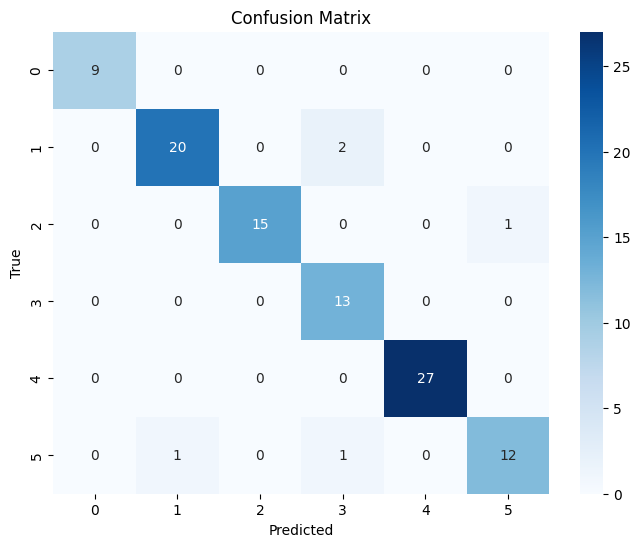

In [24]:
#Training a Decision Tree Classifier
dtc = DecisionTreeClassifier(random_state=42).fit(x_train,y_train)

# Predict on the test set
y_pred1 = dtc.predict(x_test)

print(classification_report(y_test , y_pred1 ))

cm = confusion_matrix(y_test, y_pred1)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         9
           1       1.00      0.95      0.98        22
           2       0.94      0.94      0.94        16
           3       0.93      1.00      0.96        13
           4       1.00      1.00      1.00        27
           5       0.93      0.93      0.93        14

    accuracy                           0.97       101
   macro avg       0.97      0.97      0.97       101
weighted avg       0.97      0.97      0.97       101



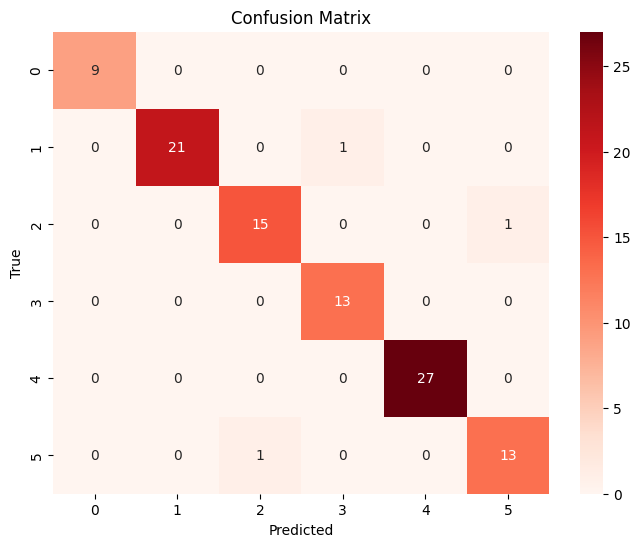

In [25]:
#Training a Random Forest Classifier
rfc = RandomForestClassifier(n_estimators = 100).fit(x_train,y_train)

# Predict on the test set
y_pred2= rfc.predict(x_test)

print(classification_report(y_test , y_pred2 ))

cm = confusion_matrix(y_test, y_pred2)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

              precision    recall  f1-score   support

           0       0.82      1.00      0.90         9
           1       1.00      0.95      0.98        22
           2       0.93      0.88      0.90        16
           3       1.00      1.00      1.00        13
           4       1.00      0.96      0.98        27
           5       0.93      1.00      0.97        14

    accuracy                           0.96       101
   macro avg       0.95      0.97      0.95       101
weighted avg       0.96      0.96      0.96       101

The best number of KNeighbors is [ 2 ]


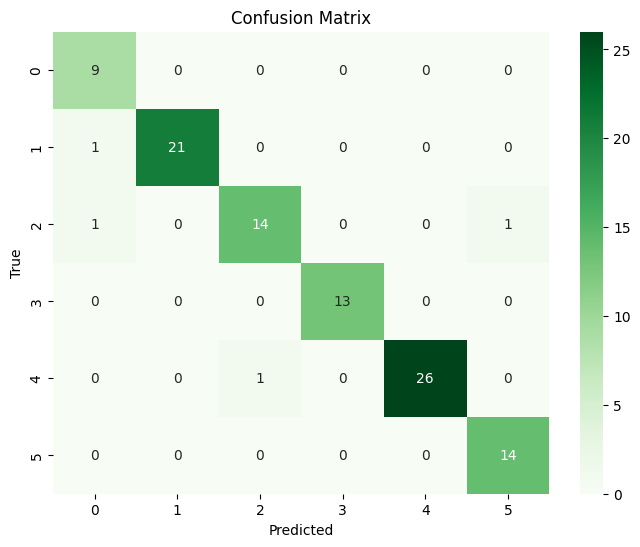

In [26]:
#Training a KNN on different KNeighbors number
def neighbors_selector(range_number):
    models = {}
    for i in range(2, range_number):
        model = KNeighborsClassifier(n_neighbors=i).fit(x_train, y_train)
        models[i] = model

    best_n_neighbors = max(models, key=lambda k: models[k].score(x_test, y_test))
    return models[best_n_neighbors],best_n_neighbors

#Saving the best model and it`s number of KNeighbors
knn , KNeighbors = neighbors_selector(10)

# Predict on the test set
y_pred3 = knn.predict(x_test)

print(classification_report(y_test , y_pred3 ))
print('The best number of KNeighbors is [',KNeighbors,']')

cm = confusion_matrix(y_test, y_pred3)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

              precision    recall  f1-score   support

           0       0.57      0.89      0.70         9
           1       0.65      0.59      0.62        22
           2       0.71      0.94      0.81        16
           3       0.92      0.92      0.92        13
           4       0.94      0.56      0.70        27
           5       0.53      0.64      0.58        14

    accuracy                           0.71       101
   macro avg       0.72      0.76      0.72       101
weighted avg       0.75      0.71      0.71       101



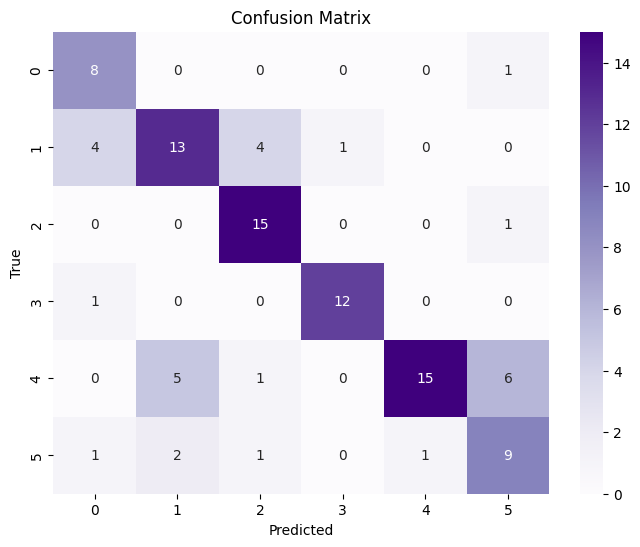

In [27]:
# Training the SVM model
svm = SVC(random_state=42).fit(x_train, y_train)

# Predict on the test set
y_pred4 = svm.predict(x_test)
print(classification_report(y_test, y_pred4, zero_division=1))

cm = confusion_matrix(y_test, y_pred4)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

In [28]:
#Saving the encoders, scalers and the wanted model(RandomForestClassifier)
joblib.dump(rfc, 'model/classifier.joblib')

joblib.dump(platform_encoder, 'encoders/platform_encoder.joblib')
joblib.dump(gender_encoder, 'encoders/gender_encoder.joblib')
joblib.dump(emotion_encoder, 'encoders/emotion_encoder.joblib')

joblib.dump(Age_scaler, 'scalers/Age_scaler.joblib')
joblib.dump(Usage_scaler, 'scalers/Usage_scaler.joblib')
joblib.dump(Posts_scaler, 'scalers/Posts_scaler.joblib')
joblib.dump(Likes_scaler, 'scalers/Likes_scaler.joblib')
joblib.dump(Comments_scaler, 'scalers/Comments_scaler.joblib')
joblib.dump(Messages_scaler, 'scalers/Messages_scaler.joblib')

['scalers/Messages_scaler.joblib']